#### Observations, baselines, and projection periods

ProFSea supports flexible baseline and projection periods, allowing sea-level projections to be expressed relative to a user-specified reference period. This notebook introduces these concepts, and shows how they interact with the `initialise_from_observations` option, which determines whether projections are initialised from observational sea-level datasets (Part 1), or generated as idealised projections that are not tied to observations (Part 2).

#### Baseline and projection periods

A baseline period defines the reference level against which sea-level change is reported. More concretely, following the convention used for sea-level projections in IPCC AR5 and AR6, a sea-level change time series $S(t)$ can be expressed relative to a chosen baseline by subtracting its mean over that period,

$S_{\rm rel}(t) = S(t) - \bar{S}_{\rm baseline}$.

This is distinct from the projection period, which defines the time period over which `ProFSea` returns sea-level projections. These are specified independently through `baseline_start`, `baseline_end`, `start_yr`, and `end_yr` when configuring the global model.

#### Two workflows: `initialise_from_observations`

Whether observations are used to initialise the model is controlled by the boolean flag `initialise_from_observations`, passed to `Global()`. This has important consequences for how baseline periods are handled.

---

**`initialise_from_observations=True`**

* The baseline period must lie within $1980-2023$, the period for which observational constraints exist for each SLR component.
* Components are initialised at their observed contribution at `start_yr`, from which projections are generated.

**`initialise_from_observations=False`**

* There are no restrictions on the baseline period, other than that it lies within the projection start and end years. This supports historical, paleo, and idealised SLR projections.
* Projections are not tied to observational data at the start year. Instead, they are re-baselined post-hoc to the mean of the projection over the specified baseline period.
* This **cannot** be used with the AR5 and AR6 components, as these are parameterised directly against their respective baseline periods.

### Part 1: Observationally-initialised projections

In this workflow, `initialise_from_observations=True`. We use the AR5 component methods available in `ProFSea` to produce illustrative AR5-like projections.

For demonstration purposes, we use a small subset of preprocessed CMIP5 GSAT and thermosteric sea-level (`zostoga`) trajectories. These data are provided purely to illustrate the ProFSea workflow (and should not be interpreted as the full ensemble used for AR5 projections!). The GSAT trajectories provide the temperature anomalies used to drive the temperature-dependent components of the projection, while `zostoga` provides the corresponding thermosteric sea-level trajectories.

It is very important that these climate-model inputs are provided relative to the same reference period that is passed to `Global()`, since the observational contributions are expressed relative to this period. Otherwise, the projections will not be self-consistent (or physically meaningful).

In [1]:
import xarray as xr

baseline_start = 1986
baseline_end = 2005

start_yr = 2006
end_yr = 2100

In [2]:
ds = xr.open_dataset("tutorial_data/gsat_zostoga_trajectories.nc")

ds

<xarray.Dataset> Size: 681kB
Dimensions:   (ensemble: 450, time: 94)
Coordinates:
  * ensemble  (ensemble) int64 4kB 0 1 2 3 4 5 6 ... 443 444 445 446 447 448 449
  * time      (time) int64 752B 2006 2007 2008 2009 2010 ... 2096 2097 2098 2099
Data variables:
    gsat      (ensemble, time) float64 338kB ...
    zostoga   (ensemble, time) float64 338kB ...
Attributes:
    scenario:  rcp85
    baseline:  1986-2005

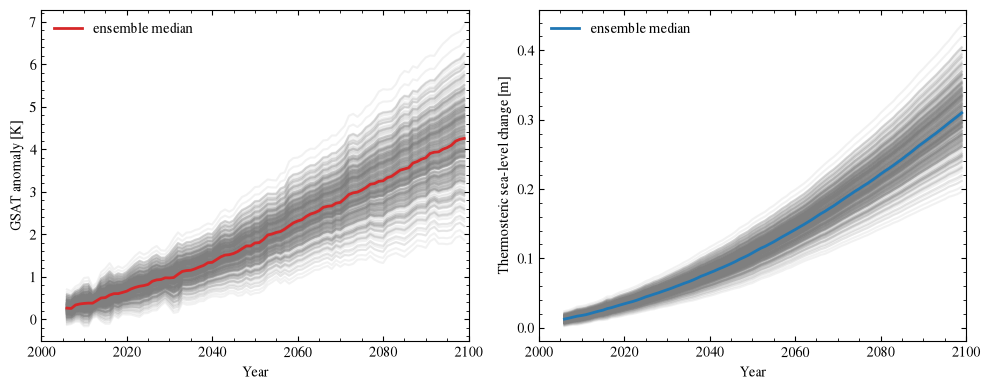

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import xarray as xr

matplotlib.rcParams['mathtext.fontset'] = 'cm'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# GSAT
axs[0].plot(
    ds.time, ds.gsat.T,
    c="tab:gray", alpha=0.1
)
axs[0].plot(
    ds.time, ds.gsat.median("ensemble"),
    c="tab:red", lw=2,
    label='ensemble median'
)
axs[0].set(
    xlabel="Year",
    ylabel="GSAT anomaly [K]",
)

# Thermosteric sea level
axs[1].plot(
    ds.time, ds.zostoga.T,
    c="tab:gray", alpha=0.1
)
axs[1].plot(
    ds.time, ds.zostoga.median("ensemble"),
    c="tab:blue", lw=2,
    label='ensemble median'
)
axs[1].set(
    xlabel="Year",
    ylabel="Thermosteric sea-level change [m]",
)

for ax in axs:
    
    ax.minorticks_on()
    ax.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
    )
    
    ax.legend(frameon=False)

    ax.set_xlim(2000, 2100)

plt.tight_layout()

plt.show()
plt.close()

#### Choosing a baseline and projection period in `ProFSea`

We use the AR5 baseline period of $1986-2005$, which the AR5 components are parameterised against, and which lies within the $1980-2023$ observational period required when `initialise_from_observations=True`. Projections are produced between $2006-2100$, with each component initialised at its observed contribution at $2006$.

To configure the global model, we first import the sea-level components used in our projection and pass them to `Global()` as a dictionary. Thermal expansion differs slightly from the other components because the preprocessed CMIP5 zostoga trajectories are supplied directly when the component is initialised.

In [4]:
from profsea.components.core.global_model import Global
from profsea.components.global_ import (
    AntarcticaDynAR5,
    AntarcticaSMBAR5,
    Glacier,
    GreenlandDynAR5,
    GreenlandSMBAR5,
    LandwaterAR5,
    ThermalExpansion,
)

global_components = {
    "landwater": LandwaterAR5(),
    "greenlandSMB": GreenlandSMBAR5(),
    "greenlandDyn": GreenlandDynAR5(),
    "expansion": ThermalExpansion(
        ds.zostoga.values,
        OHC_change=False
    ),
    "antarcticaSMB": AntarcticaSMBAR5(),
    "antarcticaDyn": AntarcticaDynAR5(),
    "glacier": Glacier(),
}

global_model = Global(
    components=global_components,
    start_yr=start_yr, 
    end_yr=end_yr,
    baseline_start=baseline_start,
    baseline_end=baseline_end,
    num_members=1000,
    initialise_from_observations=True
)

The baseline period is defined once `Global()` is initialised. Because we are initialising from observations, ProFSea creates an associated `Observations` instance, which stores the observational data (as xarray Datasets) for the requested components using this baseline. We will first read the contribution from Greenland to sea-level rise:

In [5]:
greenland = global_model.observations.greenland()

greenland

<xarray.Dataset> Size: 2kB
Dimensions:   (time: 53)
Coordinates:
  * time      (time) int64 424B 1971 1972 1973 1974 1975 ... 2020 2021 2022 2023
Data variables:
    sle       (time) float64 424B -0.001932 -0.00207 ... 0.01464 0.01511
    sle_unc   (time) float64 424B 9.927e-05 0.0001925 ... 0.001278 0.001291
    rate      (time) float64 424B -0.1832 -0.1832 -0.1626 ... 0.4584 0.4863
    rate_unc  (time) float64 424B 0.1905 0.1905 0.1857 ... 0.1446 0.1547 0.2054
Attributes:
    baseline_start:  1986
    baseline_end:    2005
    component:       total
    reference:       IMBIE3 (Otosaka et al., 2026)

We can easily plot this timeseries (and verify that it is relative to the 1986-2005 baseline!):

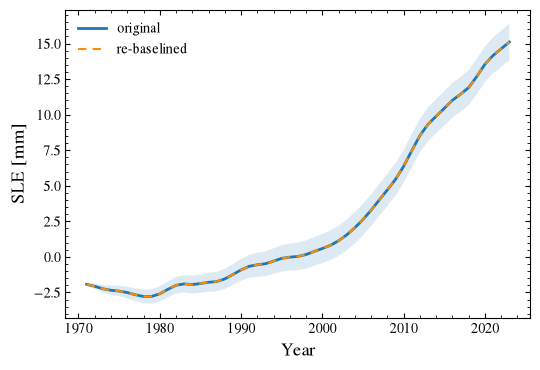

In [6]:
fig = plt.figure(figsize=(6, 4))

plt.plot(
    greenland.time,
    greenland.sle.values * 1e3,
    lw=2, label='original'
)
plt.fill_between(
    greenland.time,
    (greenland.sle.values - greenland.sle_unc.values) * 1e3,
    (greenland.sle.values + greenland.sle_unc.values) * 1e3,
    alpha=0.15, lw=0
)

greenland_baselined = (
    greenland.sle
    - greenland.sle.sel(time=slice(1986, 2005)).mean("time")
)

plt.plot(
    greenland.time,
    greenland_baselined * 1e3,
    c='darkorange', ls=(0, (4, 3)),
    label='re-baselined'
)

plt.xlabel('Year', fontsize=13)
plt.ylabel('SLE [mm]', fontsize=13)

plt.minorticks_on()
plt.tick_params(
    which='both', direction='in', 
    left=True, right=True, 
    top=True, bottom=True
)

plt.legend(frameon=False)

plt.show()

We now read in the other components, along with observed GMSL, estimated in Zheng et al., (2026; Sci. Adv.) from a composite of tide gauge reconstructions and satellite altimetry. For convenience, we store these in an observational dictionary.

In [7]:
antarctica = global_model.observations.antarctica()
glaciers = global_model.observations.glacier()
landwater = global_model.observations.landwater()
thermal_expansion = global_model.observations.thermal_expansion()
gmsl = global_model.observations.gmsl()

observations = {
    "GMSL": (gmsl, "black"),
    "Thermal Expansion": (thermal_expansion, "tab:red"),
    "Glaciers": (glaciers, "tab:brown"),
    "Landwater": (landwater, "tab:green"),
    "Greenland": (greenland, "tab:blue"),
    "Antarctica": (antarctica, "tab:orange"),
}

We can now calcualte the total component contribution to global sea level rise, which we then compare with observed GMSL.

In [8]:
total_sle = sum(
    d.sle
    for name, (d, _) in observations.items()
    if name != "GMSL"
)
total_unc = np.sqrt(
    sum(
        d.sle_unc**2
        for name, (d, _) in observations.items()
        if name != "GMSL"
    )
)

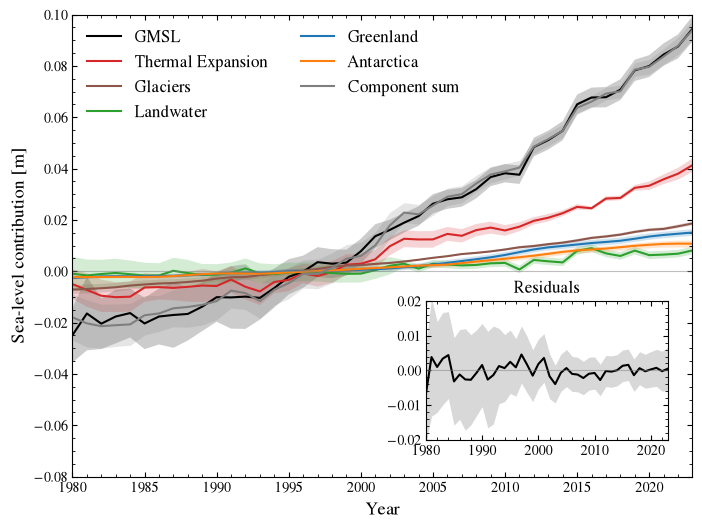

In [9]:
# Residual between observed GMSL and the component sum
gmsl_sle, total_sle, gmsl_unc, total_unc = xr.align(
    gmsl.sle, total_sle, gmsl.sle_unc, total_unc,
    join="inner",
)

# uncertainties in the residual calcualted in quadrature
residual = gmsl_sle - total_sle
residual_unc = np.sqrt(gmsl_unc**2 + total_unc**2)

fig, ax = plt.subplots(figsize=(8, 6))

series = {
    **observations,
    "Component sum": (
        xr.Dataset({"sle": total_sle, "sle_unc": total_unc}),
        "tab:gray",
    ),
}

for label, (d, color) in series.items():
    ax.plot(d.time, d.sle, color=color, label=label)
    ax.fill_between(
        d.time,
        d.sle - d.sle_unc,
        d.sle + d.sle_unc,
        color=color, alpha=0.2, lw=0,
    )

axins = ax.inset_axes([0.57, 0.08, 0.39, 0.30])
axins.plot(residual.time, residual, color="black")
axins.fill_between(
    residual.time,
    residual - residual_unc,
    residual + residual_unc,
    color="tab:gray", alpha=0.3, lw=0,
)
axins.set_title("Residuals")

for a in (ax, axins):
    a.axhline(0, color="tab:gray", lw=0.8, alpha=0.5)
    a.set_xlim(1980, 2023)
    a.minorticks_on()
    a.tick_params(which="both", direction="in", top=True, right=True)

ax.set_ylim(-0.08, 0.10)
axins.set_ylim(-0.02, 0.02)

ax.set_xlabel("Year", fontsize=13)
ax.set_ylabel("Sea-level contribution [m]", fontsize=13)

ax.legend(
    loc="upper left", ncol=2,
    frameon=False, fontsize=12
)

plt.show()
plt.close()

#### Ice sheet contributions to sea-level rise

The Greenland and Antarctic observational datasets from IMBIE 3 provide additional detail beyond the total cumulative sea-level contribution. The ice-sheet readers also allow different physical components of mass change to be selected using the `component` argument: this can be "total", "smb" (surface mass balance), or "dyn" (ice dynamics).

For Antarctica, observations can be additionally sub-divided into `region`, allowing the contributions from the East Antarctic Ice Sheet ("eais"), West Antarctic Ice Sheet ("wais"), and Antarctic Peninsula ("peninsula") to be examined separately.

For example, we can read the dynamic contribution from the West Antarctic Ice Sheet using:

In [10]:
wais_dyn = global_model.observations.antarctica(
    component="dyn",
    region="wais",
)

wais_dyn

<xarray.Dataset> Size: 2kB
Dimensions:   (time: 45)
Coordinates:
  * time      (time) int64 360B 1979 1980 1981 1982 1983 ... 2020 2021 2022 2023
Data variables:
    sle       (time) float64 360B -0.00172 -0.001529 ... 0.008945 0.009685
    sle_unc   (time) float64 360B 9.757e-05 0.0001486 ... 0.0006701 0.0007078
    rate      (time) float64 360B 0.2311 0.1576 0.08317 ... 0.3782 0.8229 0.6818
    rate_unc  (time) float64 360B 0.1387 0.07299 0.06536 ... 0.1763 0.208 0.2368
Attributes:
    baseline_start:  1986
    baseline_end:    2005
    component:       dyn
    reference:       IMBIE3 (Otosaka et al., 2026)

#### Producing projections with a consistent baseline

We have so far used a common $1986–2005$ baseline to examine the observed contribution to sea-level change from Greenland, and to build the `Global()` ProFSea instance. We can now run the simulation and visualise the global projections:

In [11]:
projections = global_model.run(
    T_change=ds.gsat.values, scenario="rcp85", member_seed=42
)
global_model.sum_components(projections)
gmslr = global_model.results["total_gmslr"]

╭──────────────────────────────────── ProFSea Global Run Configuration ─────────────────────────────────────╮
│        Scenario  rcp85                                                                                    │
│      Components  landwater, greenlandSMB, greenlandDyn, expansion, antarcticaSMB, antarcticaDyn, glacier  │
│       Timeframe  2006 -> 2100                                                                             │
│   Ensemble Size  450 inputs × 1000 draws (= 450000)                                                       │
│          Output  Full Distribution (450000 members)                                                       │
│  Compute Engine  Parallel Threading                                                                       │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Because the observational records and projections are expressed relative to a consistent $1986–2005$ baseline, their sea-level contributions can now be compared directly over their overlapping period.

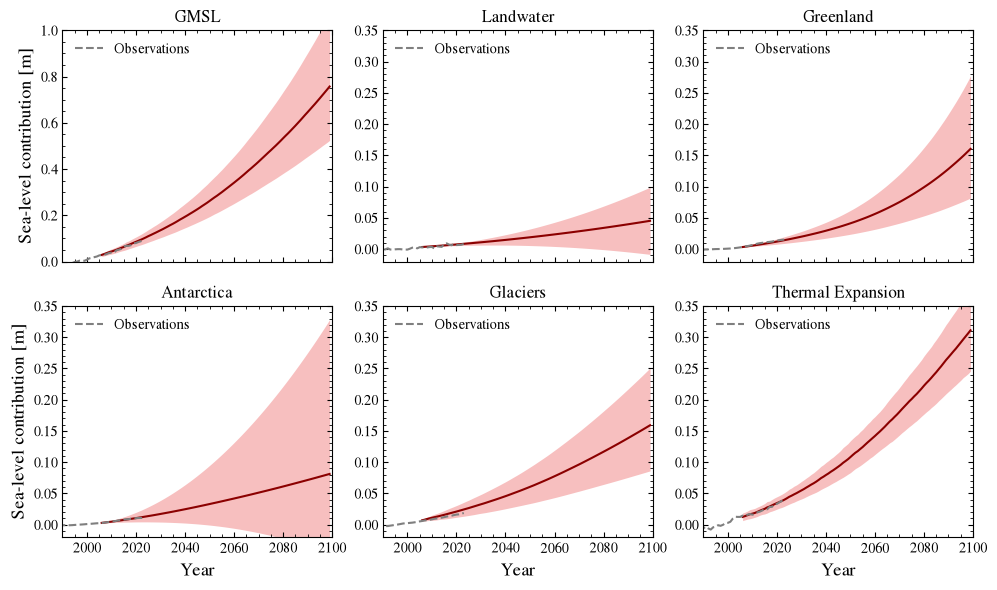

In [12]:
component_projections = {
    "GMSL": gmslr,
    "Landwater": projections["landwater"],
    "Greenland": (
        projections["greenlandSMB"]
        + projections["greenlandDyn"]
    ),
    "Antarctica": (
        projections["antarcticaSMB"]
        + projections["antarcticaDyn"]
    ),
    "Glaciers": projections["glacier"],
    "Thermal Expansion": projections["expansion"],
}

fig, axs = plt.subplots(
    2, 3,
    figsize=(10, 6),
    sharex=True,
)

axs = axs.ravel()

for ax, (label, values) in zip(axs, component_projections.items()):

    lower, upper = np.percentile(values, [5, 95], axis=(0, 1))
    mean = values.mean(axis=(0, 1))

    ax.fill_between(
        ds.time,
        lower,
        upper,
        color="lightcoral",
        alpha=0.5,
        lw=0,
    )
    ax.plot(
        ds.time,
        mean,
        color="darkred",
        lw=1.5,
    )

    if label in observations:
        obs, _ = observations[label]

        ax.plot(
            obs.time, obs.sle, c='tab:gray',
            ls='--', label='Observations'
        )

    ax.set_title(label)
    ax.minorticks_on()
    ax.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
    )

    ax.set_xlim(1990, 2100)

    ax.legend(frameon=False, loc='upper left')

for ax in axs[3:]:
    ax.set_xlabel("Year", fontsize=13)
for ax in axs[1:]:
    ax.set_ylim(-0.02, 0.35)

axs[0].set_ylim(0, 1)

axs[0].set_ylabel("Sea-level contribution [m]", fontsize=13)
axs[3].set_ylabel("Sea-level contribution [m]", fontsize=13)

plt.tight_layout()

plt.show()
plt.close()

### Part 2: Idealised projections

Setting `initialise_from_observations=False` removes the link to observational datasets, so projections can be generated for any period, for example historical, paleo, or idealised forcing experiments.

Since projections are not anchored to observations at `start_yr`, the baseline is applied post-hoc: each projection is re-baselined by subtracting its own mean over `baseline_start`–`baseline_end`. The baseline can therefore be any period within the projection start and end years, not just one covered by observations.

The AR5 and AR6 components cannot be used in this workflow, as they are parameterised directly against their respective baseline periods. Instead, we use `AntarcticaISMIP6`, `Glacier`, and `ThermalExpansion`.

---

To illustrate this functionality, we construct an idealised GSAT trajectory between $1850-2100$, which we normalise relative to a $1850-1900$ baseline.

In [13]:
start_yr = 1850
end_yr = 2100

baseline_start = 1850
baseline_end = 1900

In [14]:
t_change = np.linspace(-1, 8, 250)
t_change = t_change[None, :] * np.random.normal(
    loc=1.0, scale=0.1, size=(100, 1)
)  # add variability across members

years = np.arange(1850, 2100)
baseline_mask = (years >= 1850) & (years <= 1900)
t_change -= t_change[:, baseline_mask].mean(axis=1, keepdims=True)

ohc_change = t_change * 1e24  # in Joules
years = np.broadcast_to(years, t_change.shape)

In [15]:
from profsea.components.global_ import (
    AntarcticaISMIP6,
    Glacier,
    ThermalExpansion
)

global_components = {
    "eais": AntarcticaISMIP6(region="eais"),
    "peninsula": AntarcticaISMIP6(region="peninsula"),
    "wais": AntarcticaISMIP6(region="wais"),
    "glacier": Glacier(),
    "expansion": ThermalExpansion(ohc_change, OHC_change=True),
}

global_model = Global(
    components=global_components,
    start_yr=start_yr, 
    end_yr=end_yr,
    baseline_start=baseline_start,
    baseline_end=baseline_end,
    num_members=1000,
    initialise_from_observations=False
)

Having defined the components, we can now run this idealised scenario with a $1850-1900$ baseline:

In [16]:
projections = global_model.run(
    T_change=t_change, scenario="idealised", member_seed=42
)
global_model.sum_components(projections)
gmslr = global_model.results["total_gmslr"]

╭───────────── ProFSea Global Run Configuration ──────────────╮
│        Scenario  idealised                                  │
│      Components  eais, peninsula, wais, glacier, expansion  │
│       Timeframe  2006 -> 2100                               │
│   Ensemble Size  100 inputs × 1000 draws (= 100000)         │
│          Output  Full Distribution (100000 members)         │
│  Compute Engine  Parallel Threading                         │
╰─────────────────────────────────────────────────────────────╯

We can now visualise these idealised projections. Because `ProFSea` re-baselines the projections post-hoc, they are returned as anomalies relative to the $1850-1900$ mean. 

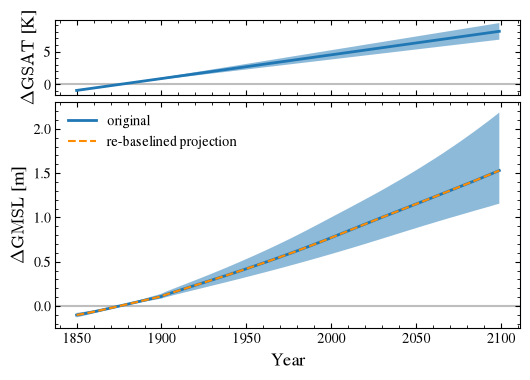

In [17]:
fig, (ax_gsat, ax_gmsl) = plt.subplots(
    2,
    1,
    figsize=(6, 4),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 3], "hspace": 0.05},
)

gsat_lower = np.percentile(t_change, 5, axis=0)
gsat_upper = np.percentile(t_change, 95, axis=0)
gsat_median = np.percentile(t_change, 50, axis=0)

ax_gsat.fill_between(
    years[0],
    gsat_lower,
    gsat_upper,
    alpha=0.5,
    lw=0,
)

ax_gsat.plot(
    years[0],
    gsat_median,
    lw=2,
)

ax_gsat.axhline(0, c="tab:gray", alpha=0.5, zorder=0)
ax_gsat.set_ylabel(r"$\Delta {\rm GSAT}$ [K]", fontsize=13)

lower = np.percentile(gmslr, 5, axis=(0, 1))
upper = np.percentile(gmslr, 95, axis=(0, 1))
median = np.percentile(gmslr, 50, axis=(0, 1))

time = years[0]
baseline_mask = (time >= 1850) & (time <= 1900)
median_rebaselined = median - median[baseline_mask].mean()

ax_gmsl.fill_between(
    years[0],
    lower,
    upper,
    alpha=0.5,
    lw=0,
)

ax_gmsl.plot(years[0], median, lw=2, label='original')
ax_gmsl.plot(
    years[0],
    median_rebaselined,
    c="darkorange",
    ls="--",
    label='re-baselined projection'
)

ax_gmsl.axhline(0, c="tab:gray", alpha=0.5, zorder=0)
ax_gmsl.set_ylabel(r"$\Delta {\rm GMSL}$ [m]", fontsize=13)
ax_gmsl.set_xlabel("Year", fontsize=13)


for ax in (ax_gsat, ax_gmsl):
    ax.minorticks_on()
    ax.tick_params(
        which="both",
        direction="in",
        left=True,
        right=True,
        top=True,
        bottom=True,
    )

ax_gmsl.legend(frameon=False)

plt.show()